<a href="https://colab.research.google.com/github/OsmanSaidO/dsa107-labs/blob/main/Lab06_Chance_samples_and_simulation_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA 107 — Lab 6: Chance, samples and simulation

**Week 6 · w/c 2 November 2026** · paired with DSA 101 lecture week 6

**Name:** Osman Said Oy   **Student ID:** 250221021029

---

### What you will produce

A runnable Colab notebook, pushed to your `dsa107-labs` repository. In it you make chance with the computer: you flip coins and roll dice, watch the law of averages, draw random samples from a real table of taxi rides, repeat a sample 10,000 times in a loop and draw one labelled figure of the results, and use a simulation to decide whether a coin result is surprising.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas numpy matplotlib seaborn` in a new cell and try again.

### How to use this notebook

Every code cell has a **Goal** written just above it. Read the goal, then write the code. You do not need to open the handout while you work — everything you have to do is in this notebook.

Every Goal and every question shows how many **points** it is worth. The table below shows how they add up to the 10 code points.

Some lines are **already written for you**. Read them, run them, and do not change them.

A code cell only shows the result of its **last line**. A value on any other line shows **nothing**. If you want to see two or more things from one cell, put each of them inside `print()`.

Some goals end with a **Check:** line. If your number is not the same as the check, fix your code before you go on.

**Random numbers and the seed.** Most cells start with a ready-made line such as `rng = np.random.default_rng(5)`. The number in the brackets is a **seed**. It makes the "random" numbers the same every time you run the cell, so your numbers can match the **Check:** lines — and your teacher gets the same numbers as you. Do not change the seed, and use the commands **in the order the Goal gives them**. If you add other random lines, your numbers will change.

The **Command reference** below holds the commands you need for this lab, and a few more. Read it once now, and come back to it whenever you are stuck.

### How the 10 code points are shared

| Part | Where in this notebook | Points |
| --- | --- | --- |
| Chance with a computer | Goals 1a, 1b (0.5 each) | 1 |
| The law of averages | Goal 2a | 1 |
| Population and sample | Goals 3a, 3b (0.5 each) | 1 |
| Many samples | Goal 4a | 1 |
| Figure | Goal 4b (needs an x label, a y label and a title) | 1 |
| Bigger samples | Goal 5a | 1 |
| The simulation recipe | Goal 6a | 1 |
| Interpretation | Q1, Q2, Q3, Q4 (0.75 each) | 3 |
| **Total** | | **10** |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("numpy", np.__version__)
print("pandas", pd.__version__)

numpy 2.4.6
pandas 2.2.3


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series). `a` means an **array**: a list of numbers made by NumPy.
Not every command here is needed for this lab — choosing the right one is part of the work.

**Making chance with NumPy — new this week**

| Command | What it does |
| --- | --- |
| `np` | NumPy, a package for working with numbers. It is loaded in the setup cell (`import numpy as np`) |
| `rng = np.random.default_rng(5)` | makes a random number generator called `rng`. The number in the brackets is the **seed**: the same seed gives the same "random" numbers every time |
| `rng.integers(0, 2, 10)` | 10 random whole numbers from 0 up to, **but not including**, 2 — so each one is 0 or 1. This is a coin: **1 = heads**, 0 = tails |
| `rng.integers(1, 7, 60)` | 60 random whole numbers from 1 to 6 — a die rolled 60 times |
| `rng.choice(a, size=50, replace=False)` | picks 50 values at random from `a`. `replace=False`: each value can be picked only **once**, like a real survey |
| `replace=True` | the same value can be picked more than once (not needed today — week 8 uses it) |

**Counting and summarising an array**

| Command | What it does |
| --- | --- |
| `a.sum()` | adds up all the values. For coin flips (0 and 1) this is the **number of heads** |
| `a.mean()` | the mean. For 0 / 1 values this is the **share** of 1s (the share of heads) |
| `a == 6` | `True` / `False` for every value: is it equal to 6? |
| `(a == 6).sum()` | **how many** values are equal to 6 |
| `(a == 6).mean()` | what **share** of the values are equal to 6 |
| `(a >= 61).mean()` | what share of the values are 61 **or more**. You can also use `>`, `<`, `<=` |
| `a.std()` | the standard deviation (SD): how spread out the values are |
| `a.min()` / `a.max()` | the smallest / the largest value |
| `len(a)` | how many values there are |
| `a[:10]` | the first 10 values |
| `np.sqrt(x)` | the square root of `x` |
| `np.percentile(a, [2.5, 97.5])` | the values that cut off the lowest 2.5% and the highest 2.5% (not needed today) |
| `round(x, 2)` | rounds one number to 2 decimal places |

**Doing it many times: the `for` loop — new this week**

| Command | What it does |
| --- | --- |
| `results = []` | makes an **empty list** called `results` |
| `for i in range(10000):` | repeats the lines **under it** 10,000 times. Do not forget the `:` at the end |
| 4 spaces at the start of a line | the lines **inside** the loop must start with 4 spaces (Colab adds them for you after the `:`) |
| `results.append(x)` | adds `x` to the end of the list `results` |
| `results = np.array(results)` | turns the list into an array, so that `.mean()`, `.std()` and `==` work on it |
| `pass` | does nothing. It only stops Python from giving an error when a loop is still empty. **Delete it** when you write your own lines |

**The taxi table**

| Command | What it does |
| --- | --- |
| `pd.read_csv(url)` | reads a CSV file into a DataFrame |
| `df.shape` / `df.head()` | (rows, columns) / the first five rows |
| `df["col"]` | one column (a Series) |
| `s.to_numpy()` | turns a column into a NumPy array |
| `s.mean()` / `s.std()` / `s.median()` | mean / standard deviation / median of one column |
| `s.sample(50)` | 50 random rows of a column — pandas' own way (not needed today; we use `rng.choice`) |

**Drawing and labelling**

| Command | What it does |
| --- | --- |
| `fig, axes = plt.subplots(1, 2)` | one figure with **two panels** side by side: `axes[0]` is the left one, `axes[1]` the right one |
| `pd.Series(a).plot.hist(bins=40, ax=axes[1])` | draws a histogram of `a` with 40 bars, in the right panel |
| `axes[1].set_xlabel("...")` | names the horizontal axis of the right panel |
| `axes[1].set_ylabel("...")` | names the vertical axis of the right panel |
| `axes[1].set_title("...")` | puts a title on the right panel |
| `axes[1].axvline(x, color="red")` | draws a vertical line at `x` |
| `plt.show()` | shows the finished figure |

A figure in this course is not finished until it has both axis labels and a title.

## 1. Chance with a computer

The lecture's question was: *is this difference real, or could it be chance?* To answer it, we first need data that comes from **nothing but chance**. A computer can make it for us.

`rng.integers(0, 2, 10)` gives 10 random numbers, each one 0 or 1. Read it as **10 flips of a fair coin**: 1 = heads, 0 = tails. The number of heads is just the **sum** of the flips.

> **Goal 1a · 0.5 pt.** Run the ready-made seed line. Flip a coin **10 times** with `rng.integers(0, 2, 10)` and store the result as `flips`. Print `flips`, then print the **number of heads**.
> **Check:** you get **7** heads.

In [2]:
rng = np.random.default_rng(7)    # ready-made line: do not change it

# TODO: flip a coin 10 times and store it as flips
flips = rng.integers(0, 2, 10)
# TODO: print flips
print(flips)
# TODO: print the number of heads
print(flips.sum())

[1 1 1 1 1 1 1 0 0 0]
7


> **Goal 1b · 0.5 pt.** Run the ready-made seed line. Roll a die **60 times** with `rng.integers(1, 7, 60)` and store the result as `rolls`. Print **how many sixes** you got, and the **share** of sixes.
> A fair die gives a six with probability 1/6 ≈ 0.17, so in 60 rolls you would expect **about 10** sixes.
> **Check:** you get **12** sixes, a share of **0.2**.

In [3]:
rng = np.random.default_rng(2)    # ready-made line: do not change it

# TODO: roll a die 60 times and store it as rolls
rolls = rng.integers(1, 7, 60)
# TODO: print how many sixes you got
print((rolls == 6).sum())
# TODO: print the share of sixes
print((rolls == 6).mean())

12
0.2


## 2. The law of averages

A probability of 0.5 for heads does **not** say what the next flip will be. It says what happens **in the long run**: if you flip many, many times, the **share** of heads settles down near 0.5. The lecture called this the **law of averages**.

You can watch it happen. Remember: for coin flips, `.mean()` gives the share of heads. So `rng.integers(0, 2, 10).mean()` flips 10 coins and gives the share of heads in **one line**.

> **Goal 2a · 1 pt.** Run the ready-made seed line. Then print the **share of heads** for **10**, **100**, **1,000** and **100,000** flips — four `print()` lines, in this order. Use `rng.integers(0, 2, n).mean()`, with the number of flips in place of `n`.
> **Check:** the share for 10 flips is **0.4**.

In [4]:
rng = np.random.default_rng(3)    # ready-made line: do not change it

# TODO: print the share of heads in 10 flips
print(rng.integers(0, 2, 10).mean())
# TODO: print the share of heads in 100 flips
print(rng.integers(0, 2, 100).mean())
# TODO: print the share of heads in 1,000 flips
print(rng.integers(0, 2, 1000).mean())
# TODO: print the share of heads in 100,000 flips
print(rng.integers(0, 2, 100000).mean())

0.4
0.51
0.492
0.49996


**Q1 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) Fill in: 10 coin flips gave 7 heads. 60 die rolls gave 12 sixes, a share of 0.2. The share of heads was 0.4 for 10 flips, 0.51 for 100 flips, 0.492 for 1,000 flips and 0.49996 for 100,000 flips.
(b) A fair die gives a six with probability 1/6 ≈ 0.17, but your share of sixes is not 0.17. Does this mean the die is not fair? Explain why.
(c) Which number of flips gave the share **closest** to 0.5? What does this tell you about what a probability of 0.5 means?

(b) No, it does not mean the die is unfair. In a small sample (60 rolls), random variation naturally causes the observed share to deviate from the theoretical probability ($1/6 \approx 0.17$).
(c) 100,000 flips gave the share closest to 0.5. This illustrates the law of averages: a probability of 0.5 describes long-run behavior over many repetitions, not short-term outcomes.

## 3. Population and sample

Coins and dice are made up. Now we use a **real table**: **6,433 taxi rides in New York City** in March 2019 (yellow and green taxis). In this lab we treat these 6,433 rides as the **whole population** — every ride we want to say something about.

| Column | What it means |
| --- | --- |
| `pickup` | the date and time the ride started |
| `distance` | the length of the ride, in miles (1 mile ≈ 1.6 km) |
| `fare` | the price of the ride in US dollars, without the tip and the tolls |
| `tip` | the tip the passenger gave, in dollars |
| `color` | `yellow` or `green` taxi |
| `payment` | `cash` or `credit card` |

Four words from the lecture:

| Word | Meaning | In this lab |
| --- | --- | --- |
| **Population** | everyone or everything you want to say something about | all 6,433 rides |
| **Sample** | the part of it you actually measured | 50 rides picked at random |
| **Parameter** | a number that describes the **population**. Usually we do not know it | the mean fare of all 6,433 rides |
| **Statistic** | a number computed from your **sample**. It moves every time you take a new sample | the mean fare of your 50 rides |

In real life you almost never know the parameter. Here we **do** know it — so we can see how close the statistics get to it.

> **Goal 3a · 0.5 pt.** Run the ready-made lines: they load the table as `taxis`, show its shape and its first rows, and store the fares as an array called `fares`. Then print the **mean fare** and the **SD of the fare** of the whole population, each rounded to 2 decimal places.
> **Check:** the mean fare is **13.09** dollars.

In [5]:
# ready-made lines: do not change them
taxis_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"
taxis = pd.read_csv(taxis_url)
print("shape:", taxis.shape)
print(taxis.head())
fares = taxis["fare"].to_numpy()       # the 6,433 fares as an array
print()

# TODO: print the mean fare of all rides (rounded to 2 decimals)
print(round((taxis["fare"].mean()),2))
# TODO: print the SD of the fare of all rides (rounded to 2 decimals)
print(round((taxis["fare"].std()),2))

shape: (6433, 14)
                pickup              dropoff  passengers  distance  fare   tip  tolls  total   color      payment            pickup_zone           dropoff_zone pickup_borough dropoff_borough
0  2019-03-23 20:21:09  2019-03-23 20:27:24           1      1.60   7.0  2.15    0.0  12.95  yellow  credit card        Lenox Hill West    UN/Turtle Bay South      Manhattan       Manhattan
1  2019-03-04 16:11:55  2019-03-04 16:19:00           1      0.79   5.0  0.00    0.0   9.30  yellow         cash  Upper West Side South  Upper West Side South      Manhattan       Manhattan
2  2019-03-27 17:53:01  2019-03-27 18:00:25           1      1.37   7.5  2.36    0.0  14.16  yellow  credit card          Alphabet City           West Village      Manhattan       Manhattan
3  2019-03-10 01:23:59  2019-03-10 01:49:51           1      7.70  27.0  6.15    0.0  36.95  yellow  credit card              Hudson Sq         Yorkville West      Manhattan       Manhattan
4  2019-03-30 13:27:42  2019-03-

> **Goal 3b · 0.5 pt.** Run the ready-made seed line. Draw **one random sample of 50 rides**: `rng.choice(fares, size=50, replace=False)`, and store it as `sample1`. Print its **mean**, rounded to 2 decimals.
> Then do it **again** with a new line: draw a second sample of 50 and store it as `sample2`, and print its mean.
> **Check:** the mean of `sample1` is **13.32**.

In [6]:
rng = np.random.default_rng(4)    # ready-made line: do not change it

# TODO: draw a sample of 50 fares (replace=False) and store it as sample1
sample1 = rng.choice(fares, size=50, replace=False)
# TODO: print the mean of sample1 (rounded to 2 decimals)
print(round((sample1.mean()),2))
# TODO: draw a second sample of 50 fares and store it as sample2
sample2 = rng.choice(fares, size=50, replace=False)
# TODO: print the mean of sample2 (rounded to 2 decimals)
print(round((sample2.mean()),2))

13.32
14.67


**Q2 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) Fill in: the population has 6433 rides. The mean fare of all rides is 13.09 dollars. Sample 1 has a mean fare of 13.32 dollars, and sample 2 has a mean fare of 14.67 dollars.
(b) Look at the three means in (a). Which one is a **parameter**, and which ones are **statistics**?
(c) You used the same population and the same sample size two times. Why are the two sample means **different**?

(b) The population mean (13.09) is a parameter; the means of Sample 1 (13.32) and Sample 2 (14.67) are statistics.

(c) Each sample contains a different random subset of 50 rides (sampling variability/chance variation).

## 4. Many samples: the distribution of a statistic

One sample tells you little. **Many** samples tell you a lot. The lecture's plan:

1. Take a sample and compute its mean.
2. Do it again — and again — **10,000 times**.
3. Collect the 10,000 means in a list.
4. Draw them. The shape you get is the **distribution of the statistic** (the distribution of the sample mean).

To do something 10,000 times, you do not write 10,000 lines. You write a **`for` loop**. Here is a small one. Run it (no points):

- `squares = []` makes an empty list.
- `for i in range(5):` repeats the lines under it 5 times. `i` is 0 the first time, then 1, 2, 3, 4.
- The line **inside** the loop starts with **4 spaces**. That is how Python knows it belongs to the loop.
- `squares.append(i * i)` adds one number to the end of the list each time.

In [7]:
# ready-made example: run it, no points
squares = []
for i in range(5):
    squares.append(i * i)
print(squares)

[0, 1, 4, 9, 16]


> **Goal 4a · 1 pt.** Fill in the loop. **Inside** the loop (4 spaces at the start of each line), write two lines:
> 1. draw a sample of 50 fares with `rng.choice(fares, size=50, replace=False)` and store it as `sample`;
> 2. add the **mean** of `sample` to the list `means` with `means.append(...)`.
>
> Delete the `pass` line. After the loop, the ready-made lines turn the list into an array and print how many means you have. Then print the **mean** of the 10,000 sample means and their **SD**, each rounded to 2 decimals.
> **Check:** you have **10000** sample means; their mean is close to the population mean (**13.09**), and their SD is about **1.65**.

In [8]:
rng = np.random.default_rng(5)    # ready-made line: do not change it
means = []                        # ready-made line: an empty list

for i in range(10000):
    # TODO: draw a sample of 50 fares (replace=False) and store it as sample
    sample = rng.choice(fares, size=50, replace=False)
    # TODO: add the mean of sample to the list means
    means.append(sample.mean())
    pass    # delete this line when you have written your two lines

# ready-made lines: do not change them
means = np.array(means)
print("number of sample means:", len(means))

# TODO: print the mean of the 10,000 sample means (rounded to 2 decimals)
print(round((means.mean()),2))
# TODO: print the SD of the 10,000 sample means (rounded to 2 decimals)
print(round((means.std()),2))

number of sample means: 10000
13.09
1.65


The lecture warned: **the distribution of the data** and **the distribution of the statistic** are two different pictures, and mixing them up is the most common mistake in this part of the course.

- **The data:** one value per **ride** — 6,433 fares.
- **The statistic:** one value per **sample** — 10,000 means, each one the mean of 50 fares.

The next figure puts them side by side, on the **same** horizontal axis. The left panel is ready-made. You draw the right panel. The red line in both panels is the population mean. (32 rides with a fare above 60 dollars are off the left picture.)

> **Goal 4b · Figure · 1 pt.** In the **right** panel (`ax=axes[1]`), draw a **histogram** of your 10,000 sample means with 40 bars: `pd.Series(means).plot.hist(bins=40, ax=axes[1])`. Give the right panel an x label, a y label and a title.

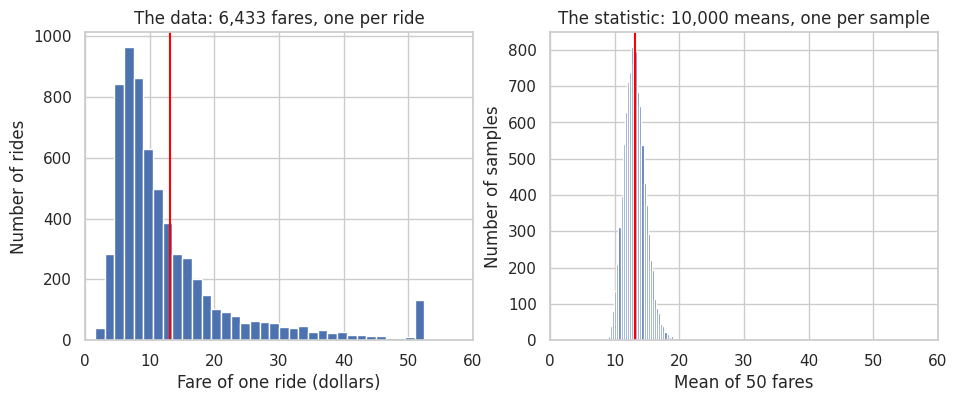

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

# ready-made lines: the left panel shows the DATA (one value per ride)
taxis["fare"].plot.hist(bins=40, range=(0, 60), ax=axes[0])
axes[0].set_xlabel("Fare of one ride (dollars)")
axes[0].set_ylabel("Number of rides")
axes[0].set_title("The data: 6,433 fares, one per ride")
axes[0].axvline(taxis["fare"].mean(), color="red")

# TODO: right panel: histogram of the 10,000 sample means (bins=40, ax=axes[1])
pd.Series(means).plot.hist(bins=40, ax=axes[1])
# TODO: x label, y label and title for axes[1]
axes[1].set_xlabel("Mean of 50 fares")
axes[1].set_ylabel("Number of samples")
axes[1].set_title("The statistic: 10,000 means, one per sample")

# ready-made lines: do not change them
axes[1].axvline(taxis["fare"].mean(), color="red")
axes[0].set_xlim(0, 60)
plt.show()

## 5. Bigger samples

What happens to the sample means if every sample is **bigger**? Run the same loop again, but with samples of **200** rides instead of 50.

The lecture gave **one formula** for this, the **square root law**:

> SD of the sample mean ≈ SD of the population ÷ √(sample size)

The ready-made lines at the top of the next cell compute this formula for 50 and for 200, so you can compare it with your simulation.

> **Goal 5a · 1 pt.** Copy your loop from Goal 4a into the loop below, and change **50** into **200**. Store the means in the list `means_200` (not `means`). Delete the `pass` line.
> After the loop, print the **SD** of the sample means for samples of **50** (`means`, from Goal 4a) and for samples of **200** (`means_200`), each rounded to 2 decimals. Then print the **ratio**: the SD for 50 divided by the SD for 200, rounded to 2 decimals.
> **Check:** the SD for samples of 200 is about **0.80**, and the ratio is about **2**.

In [10]:
# ready-made lines: do not change them
print("square root law, samples of 50: ", round(taxis["fare"].std() / np.sqrt(50), 2))
print("square root law, samples of 200:", round(taxis["fare"].std() / np.sqrt(200), 2))
print()
rng = np.random.default_rng(6)
means_200 = []

for i in range(10000):
    # TODO: draw a sample of 200 fares (replace=False) and store it as sample
    sample = rng.choice(fares, size=200, replace=False)
    # TODO: add the mean of sample to the list means_200
    means_200.append(sample.mean())
    pass    # delete this line when you have written your two lines

# ready-made line: do not change it
means_200 = np.array(means_200)

# TODO: print the SD of means (samples of 50), rounded to 2 decimals
print(round((means.std()),2))
# TODO: print the SD of means_200 (samples of 200), rounded to 2 decimals
print(round((means_200.std()),2))
# TODO: print the ratio: SD for 50 divided by SD for 200, rounded to 2 decimals
print(round((means.std()/means_200.std()),2))

square root law, samples of 50:  1.63
square root law, samples of 200: 0.82

1.65
0.8
2.05


**Q3 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) Fill in: the mean of the 10,000 sample means is 13.09 dollars (the population mean is 13.09 dollars). The SD of the sample means is 1.65 for samples of 50 and 0.80 for samples of 200. The ratio is 2.05.
(b) Look at the two panels of the figure in Goal 4b. Which panel is **much narrower**? Why? (Hint: one value per ride, or one value per sample?)
(c) The samples of 200 are **4 times** bigger than the samples of 50. Did the SD of the sample means become 4 times smaller? Explain with the square root law.

(b) The right panel is much narrower. The left panel shows variation across individual rides (data), while the right panel shows sample means (averages of 50 rides), where high and low fares cancel each other out.

(c) No, it became 2 times smaller, not 4.
According to the square root law, dividing by the square root of 4 ($\sqrt{4}$) cuts the SD in half ($\sqrt{4} = 2$).

## 6. The simulation recipe: is the coin fair?

Your friend says her coin is fair. You flip it **100 times** and get **61 heads**. A fair coin should give about 50. Is 61 suspicious, or just chance?

The lecture's **four-step recipe** answers this kind of question:

| Step | In general | Here |
| --- | --- | --- |
| 1. State the chance model | What would the world look like if nothing interesting were happening? | The coin is **fair**: heads has probability 0.5. So `rng.integers(0, 2, 100)` is 100 flips of a fair coin |
| 2. Choose a statistic | One number that would be large if something interesting **were** happening | The **number of heads** in 100 flips |
| 3. Simulate it many times | Make data under the model, compute the statistic, repeat 10,000 times | 10,000 times: flip a fair coin 100 times and count the heads |
| 4. Compare | Where does the value you saw sit among the simulated ones? | What **share** of the 10,000 simulations gave **61 or more** heads? |

Notice the question we can answer. It is **not** "is the coin unfair?" It is: **"how often would a fair coin do this?"**

For comparison, a second friend got **55 heads** in 100 flips. You check that number too.

> **Goal 6a · 1 pt.** Fill in the loop. **Inside** the loop, write two lines:
> 1. flip a fair coin **100** times with `rng.integers(0, 2, 100)` and store it as `flips`;
> 2. add the **number of heads** (`flips.sum()`) to the list `counts`.
>
> Delete the `pass` line. After the loop, print the **mean** of `counts`. Then print the **share** of simulations with **61 or more** heads, and the share with **55 or more** heads.
> **Check:** the mean is about **50**, and the share with 61 or more heads is about **0.02**.

In [11]:
rng = np.random.default_rng(1)    # ready-made line: do not change it
counts = []                       # ready-made line: an empty list

for i in range(10000):
    # TODO: flip a fair coin 100 times and store it as flips4
    flips = rng.integers(0, 2, 100)
    # TODO: add the number of heads to the list counts
    counts.append(flips.sum())
    pass    # delete this line when you have written your two lines

# ready-made line: do not change it
counts = np.array(counts)

# TODO: print the mean of counts
print(counts.mean())
# TODO: print the share of simulations with 61 or more heads
print((counts >= 61).mean())
# TODO: print the share of simulations with 55 or more heads
print((counts >= 55).mean())

49.9956
0.0168
0.1833


Run the ready-made cell below to **see** your simulation (no points). Each bar shows how many of the 10,000 simulations gave that number of heads. The red line is at 61 heads, the orange line at 55.

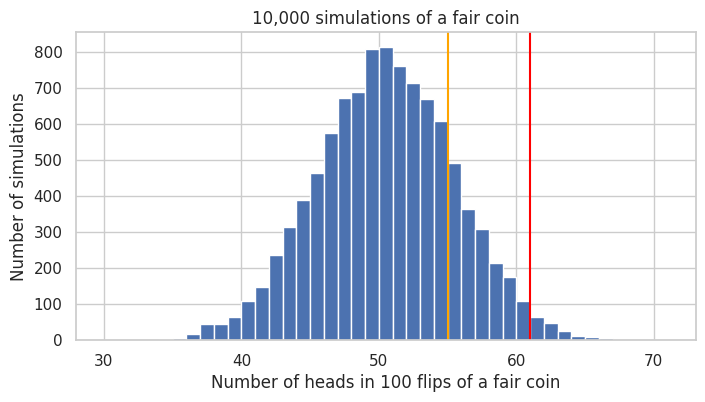

In [12]:
# ready-made cell: run it, no points
plt.figure(figsize=(8, 4))
ax = pd.Series(counts, dtype=float).plot.hist(bins=range(30, 72))
ax.axvline(61, color="red")
ax.axvline(55, color="orange")
ax.set_xlabel("Number of heads in 100 flips of a fair coin")
ax.set_ylabel("Number of simulations")
ax.set_title("10,000 simulations of a fair coin")
plt.show()

**Q4 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) Fill in: in 100 flips, a fair coin gave 49.9956 heads on average. The share of simulations with 61 or more heads was 0.0168, and the share with 55 or more heads was 0.1833.
(b) Your friend got 61 heads. Is that **surprising** for a fair coin? Use the share in your answer.
(c) Your second friend got 55 heads. Is that **good evidence** that her coin is not fair? Use the share in your answer.

(b) Yes, it is surprising. A fair coin produces 61 or more heads only about 1.8% to 2% of the time ($p \approx 0.02$), which is an unusual outcome.

(c) No, this is not good evidence. Getting 55 or more heads happens roughly 18.5% of the time purely by chance under a fair coin model, which is fairly common.

## 7. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:** https://github.com/OsmanSaidO/dsa107-labs.git

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] No `pass` line is left in a loop that you filled in, and every **Check:** line gives the number it should
- [ ] The figure (Goal 4b) has an x label, a y label and a title on the right panel
- [ ] All four written answers (Q1–Q4) are filled in — a figure or a table with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab06_Firstname_Lastname.ipynb`
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.